LAB 5: Feature Selection, Cross-Validation, and Model Complexity 

In [1]:
#importing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.preprocessing import SplineTransformer
from sklearn.base import clone



#uploading csv for cars
auto = pd.read_csv("../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)
auto

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
387,27.0,4,140.0,86.0,2790,15.6,82,1,ford mustang gl
388,44.0,4,97.0,52.0,2130,24.6,82,2,vw pickup
389,32.0,4,135.0,84.0,2295,11.6,82,1,dodge rampage
390,28.0,4,120.0,79.0,2625,18.6,82,1,ford ranger


PART 1: Feature Selection (10 pts) 

Question 1: Data pre-processing + exploration:

1a) As noted above, we are going to treat cylinders as a categorical variable. Count how many unique records there are for each cylinder type. Then, calculate and use a boxplot to show the the distribution of mpg for each cylinder count. 

In [2]:
#counting the number of cars for each cylinder count
auto["cylinders"].value_counts().sort_index()

cylinders
3      4
4    199
5      3
6     83
8    103
Name: count, dtype: int64

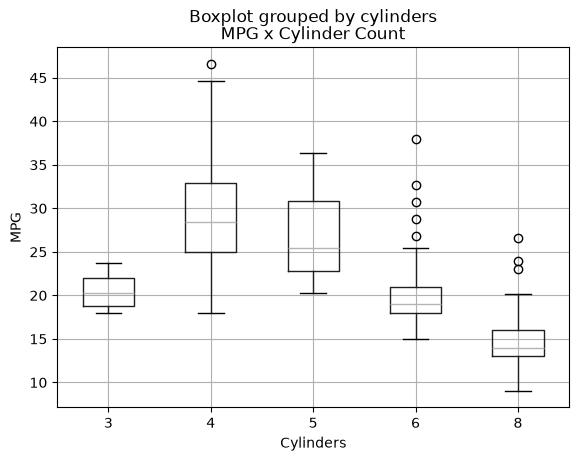

In [3]:
#boxplot
auto.boxplot(column="mpg", by="cylinders")
plt.xlabel("Cylinders")
plt.ylabel("MPG")
plt.title("MPG x Cylinder Count")
plt.show()


1b) Create a new categorical variable called “cyl_rollup” and create the following categories 
i. < 6 cylinders 
ii. 6 cylinders 
iii. 8 cylinders 

In [4]:
#new category 
auto["cyl_rollup"] = auto["cylinders"].astype(str)

#other categories
auto.loc[auto["cylinders"] < 6, "cyl_rollup"] = "<6"
auto.loc[auto["cylinders"] == 6, "cyl_rollup"] = "6"
auto.loc[auto["cylinders"] == 8, "cyl_rollup"] = "8"

#new dataframe with new category
auto["cyl_rollup"].value_counts()

cyl_rollup
<6    206
8     103
6      83
Name: count, dtype: int64

1c) Add this new category to the auto data frame and create the same plot as in part a, 
replacing cylinders with cyl_rollup. What do you observe? 
ANSWER: 
- < 6 cylinders: presents the highest median for MPG like around 28 and has a long spread compared to the other two
- 6 cylinders: has a short spread and presents a median of like 19
- 8 cylinders: presents the lowest median like around 14 and has a short spread

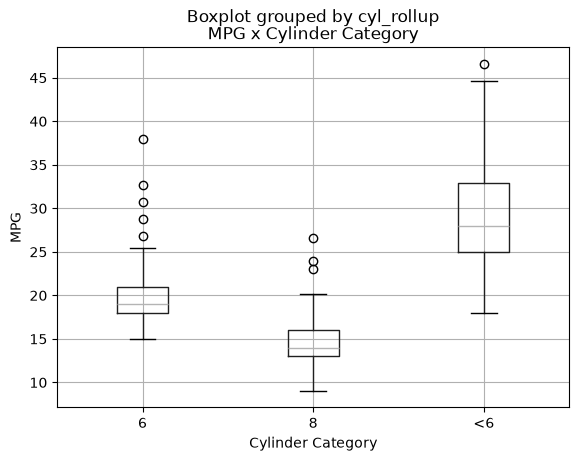

In [5]:
#dataframe with new category
auto["cyl_rollup"].value_counts()

#boxplot with cyl_rollup
auto.boxplot(column="mpg", by="cyl_rollup")
plt.xlabel("Cylinder Category")
plt.ylabel("MPG")
plt.title("MPG x Cylinder Category")
plt.show()

1d) Why should we exclude “name” from the dataset?
ANSWER:
- We should exclude the "name" column from the dataset because it is more of a categorical category. It presents car brands, which has no numerical value behind it.

Question 2: Now we will do forward and backward feature selection. For this section, use only the 
numeric variables in the data frame: ["displacement", "horsepower", "weight", "acceleration", "year"]. 
Use StandardScaler to scale the variables as we did in Lab4 and in class examples. Note that you 
will also need to create a KFold cross validation object for this section. Use the same KFold object 
for both parts a and b  

2a) Run forward selection with SequentialFeatureSelector, LinearRegression(), direction="forward", 
and n_features_to_select=k for k = 1, 2, ..., 4. For each value of k, print out which features are 
selected. This will tell you the order in which the features are selected. 

AI

In [6]:
#variables for forward feature selection
features = ["displacement", "horsepower", "weight", "acceleration", "year"]

X = auto[features]
y = auto["mpg"]

In [7]:
#standard scaler
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)


In [8]:
#kfold
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [9]:
#forward selection
for k in range(1, 5):
    sfs = SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=k,
        direction="forward",
        cv=kf
    )

    sfs.fit(X_scaled, y)
    print(f"{k} features: {X_scaled.columns[sfs.get_support()].tolist()}")

1 features: ['weight']
2 features: ['weight', 'year']
3 features: ['displacement', 'weight', 'year']
4 features: ['displacement', 'horsepower', 'weight', 'year']


2b) Run backward selection with n_features_to_select=3. Do forward and backward selection 
choose the same three features? If they do, does that guarantee that they found the best 
model? If they don’t, why not? 
ANSWER:
Forward and backward selection choose the same three features. It does not guarantee the best model just because both select the same features. 


In [10]:
#backward feature selection

sfs_backward = SequentialFeatureSelector(
    LinearRegression(),
    n_features_to_select=3,
    direction="backward",
    cv=kf
)

sfs_backward.fit(X_scaled, y)

print(X_scaled.columns[sfs_backward.get_support()].tolist())

['displacement', 'weight', 'year']


2c) Look at the correlations between displacement, horsepower, and weight and calculate 
their VIFs, as we did in Lab 3. (Feel free to use statsmodels for this.) For variables with 
high VIF numbers, how can this affect the features chosen for Backward Selection? What 
about forward selection? 
ANSWER: 
Variables with high VIF numbers, when features are chosen for backward selection it shows similar results when they are correlated meaning that if one is taken out it doesn't impact the model, while when features are chosen for forward selection it shows one similar result/correlation this means that if another one is added it doesn't impact the model.

In [11]:
#correlation matrix for displacement, horsepower, and weight
auto[["displacement", "horsepower", "weight"]].corr()

,displacement,horsepower,weight
displacement,1.000000,0.897257,0.932994
horsepower,0.897257,1.000000,0.864538
weight,0.932994,0.864538,1.000000


In [12]:
#VIF
X_vif = auto[["displacement", "horsepower", "weight"]]
X_vif = sm.add_constant(X_vif)

for i in range(1, X_vif.shape[1]):
    print(X_vif.columns[i], variance_inflation_factor(X_vif.values, i))


displacement 10.310539460377477
horsepower 5.287295179968007
weight 7.95738343111611


AI USAGE:
Use of AI for question 2 
I used GenAI to help explain concepts, such as scaler, foward, and backwards selection, by suggesting a beginner friendly way to approach the problem. I did not rely on the generated answers without checking them with my class notebook examples and slides and I tested the code in Jupyter Notebook.

PART 2: Cross-Validation Approaches 

Question 1: [3pts] First, we will build each of these models using a single train/test split, with 80% training 
and 20% testing.  

1a) Build Models A and B with LinearRegression using only the training data. Calculate the 
RMSE for both the training (in-sample) and testing (out of sample) data. Create a table 
that compares the train and test error for each of these Models. 

In [13]:
auto.columns

Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'year', 'origin', 'name', 'cyl_rollup'],
      dtype='str')

In [14]:
auto["cyl_rollup"] = auto["cylinders"].astype(str)

auto.loc[auto["cylinders"] < 6, "cyl_rollup"] = "<6"
auto.loc[auto["cylinders"] == 6, "cyl_rollup"] = "6"
auto.loc[auto["cylinders"] == 8, "cyl_rollup"] = "8"

In [15]:
# Model A
X_A = auto[["displacement", "weight", "year"]]

# Model B
X_B = auto[["displacement", "weight", "year", "cyl_rollup", "origin"]]

# Target
y = auto["mpg"]

In [16]:
#train test split
X_A_train, X_A_test, y_train, y_test = train_test_split(
    X_A, y, test_size=0.2, random_state=42
)

X_B_train, X_B_test = X_B.loc[X_A_train.index], X_B.loc[X_A_test.index]


In [17]:
#Build Model A
model_A = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

model_A.fit(X_A_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['displacement','weight','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [18]:
#Build model B
numeric_features = ["displacement", "weight", "year"]
categorical_features = ["cyl_rollup", "origin"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features)
])

model_B = make_pipeline(
    preprocessor,
    LinearRegression()
)

model_B.fit(X_B_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['displacement','weight','year','cyl_rollup','origin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis 

In [19]:
#RMSE

# Model A
rmse_A_train = root_mean_squared_error(y_train, model_A.predict(X_A_train))
rmse_A_test = root_mean_squared_error(y_test, model_A.predict(X_A_test))

# Model B
rmse_B_train = root_mean_squared_error(y_train, model_B.predict(X_B_train))
rmse_B_test = root_mean_squared_error(y_test, model_B.predict(X_B_test))


In [20]:
#comparison table
results = pd.DataFrame({
    "Model": ["A", "B"],
    "Training RMSE": [rmse_A_train, rmse_B_train],
    "Testing RMSE": [rmse_A_test, rmse_B_test]
})

results


,Model,Training RMSE,Testing RMSE
0,A,3.460333,3.261195
1,B,3.225824,3.088636


1b) Which model would you say is better and why? 
ANSWER: 
Model B is better because it has a lower training RMSE 3.23 and testing RMSE 3.09 compared to Model A training RMSE 3.46 and and testing RMSE 3.26. 
This is because in Model B it presents additional catergories providing the training and tetsing RMSE to be higher than Model A. 

Question 2: Now we will use k-fold cross validation with LinearRegression to build Models A and B  

2a) Build each model with 5-fold and 10-fold cross-validation. 

In [21]:
#cross validation
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)
kf10 = KFold(n_splits=10, shuffle=True, random_state=42)

In [22]:
#RMSE for cross validation
# Model A 5 fold and 10 fold cross validation
cv5_A = -cross_val_score(model_A, X_A, y, cv=kf5, scoring="neg_root_mean_squared_error")
cv10_A = -cross_val_score(model_A, X_A, y, cv=kf10, scoring="neg_root_mean_squared_error")

# Model B 5 fold and 10 fold cross validation
cv5_B = -cross_val_score(model_B, X_B, y, cv=kf5, scoring="neg_root_mean_squared_error")
cv10_B = -cross_val_score(model_B, X_B, y, cv=kf10, scoring="neg_root_mean_squared_error")


print("Model A - 5-fold RMSE:", cv5_A.mean())
print("Model A - 10-fold RMSE:", cv10_A.mean())

print("Model B - 5-fold RMSE:", cv5_B.mean())
print("Model B - 10-fold RMSE:", cv10_B.mean())

Model A - 5-fold RMSE: 3.421725022465226
Model A - 10-fold RMSE: 3.3912066840460966
Model B - 5-fold RMSE: 3.234639491197131
Model B - 10-fold RMSE: 3.2047125887244285


2b) For each model, compare the out of sample RMSE that was calculated in Question 1 
(single train/test split), 5-fold cross-validation, and 10-fold cross validation. What 
patterns do you see? 
ANSWER:
- Model A has a higher RMSE than Model B. Model B presents a loweer RMSE across all of them. 
- Model A and Model B both show a lower RMSE during the 10-fold cross validation vs 5-fold cross validation. 

2c) Which model would you now say is better and why? 
I would say Model B is better because throughout all their RMSE it shows consistantly lower RMSE than Model A. This is because in Model B presents additional categories providing the training, testing, 10 fold, and 5 fold RMSE to be lower than Model A. 

Question 3: Finally, we want to repeat questions 1 and 2 with 100 different random seeds, similar to 
what we did in the feat_selection_pt3_cross_validation.ipynb notebook. The code to do this is in Part 
1 of this in class notebook. I would like you to generate the plot entitled RMSE estimates across 
100 random seeds for Models A and B. Note: You do NOT have to do repeated k-fold or 
LOOCV for this exercise. You will need to make a slight change to the plotting code to do this. 

3a) Based on these plots, which model would you choose and why?
ANSWER:
I would chose Model B:
- Model B has a lower median RMSE than Model A. 
- Model B has a lower prediction errors

In [23]:
#storing RMSE values for 100 random seeds
rmse_A_100 = []
rmse_B_100 = []

In [24]:
#100 random seeds repeat
for seed in range(100):

    #train/test split
    X_A_train, X_A_test, y_train, y_test = train_test_split(
        X_A, y, test_size=0.2, random_state=seed
    )

    X_B_train = X_B.loc[X_A_train.index]
    X_B_test = X_B.loc[X_A_test.index]

    #Model A
    model_A.fit(X_A_train, y_train)
    rmse_A = root_mean_squared_error(
        y_test, model_A.predict(X_A_test)
    )
    rmse_A_100.append(rmse_A)

    #Model B
    model_B.fit(X_B_train, y_train)
    rmse_B = root_mean_squared_error(
        y_test, model_B.predict(X_B_test)
    )
    rmse_B_100.append(rmse_B)


print(len(rmse_A_100))
print(len(rmse_B_100))

100
100


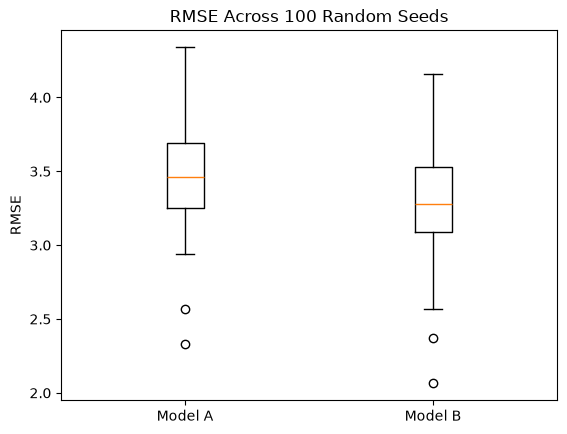

In [25]:
#boxplots
plt.boxplot([rmse_A_100, rmse_B_100],
            tick_labels=["Model A", "Model B"])

plt.ylabel("RMSE")
plt.title("RMSE Across 100 Random Seeds")
plt.show()

3b) Is adding the categorical variables worth the extra complexity? (Note: There are multiple correct answers for this one!) 
ANSWER: 
Yes, adding the categorical variables is worth the extra complexity because Model B overall demonstrates overall lower RMSE then Model A. This shows that predictions are improved when additional categorical varibles are added to the model. 

AI USAGE:
Use of AI for question 1, 2, and 3 
I used GenAI to help explain concepts, such as RMSE, train/test split, and cross validation, by suggesting a beginner friendly way to approach the problem. I did not rely on the generated answers without checking them with my class notebook examples and slides and I tested the code in Jupyter Notebook.

PART 3: Polynomial and Spline Regression (15 pts) 

Question 1: 5 pts] Using the bike sharing data, fit three models predicting daily bike rentals as a function of 
temperature. Use a single 80/20 train/test split. 

In [26]:
#loading data
bike = pd.read_csv("../data/bike-sharing-daily.csv")
bike

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796


1a) Model A: Standard Linear Regression 

In [27]:
#Model A
X = bike[["temp"]]
y = bike["cnt"]

In [28]:
#80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [29]:
#standard linear regression
model_A = LinearRegression()
model_A.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[6575.39]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['temp']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1272
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [30]:
#Model A predictions
y_train_pred_A = model_A.predict(X_train)
y_test_pred_A = model_A.predict(X_test)

#Model A RMSE
train_rmse_A = root_mean_squared_error(y_train, y_train_pred_A)
test_rmse_A = root_mean_squared_error(y_test, y_test_pred_A)

print("Model A Training RMSE:", train_rmse_A)
print("Model A Testing RMSE:", test_rmse_A)

Model A Training RMSE: 1497.6746899211785
Model A Testing RMSE: 1546.3026500758826


1b) Model B: Polynomial, degree = 9

In [31]:
#Model B
model_B = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=9, include_bias=False),
    LinearRegression()
)

model_B.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['temp']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [32]:
#Model B predictions
y_train_pred_B = model_B.predict(X_train)
y_test_pred_B = model_B.predict(X_test)

#Model B RMSE
train_rmse_B = root_mean_squared_error(y_train, y_train_pred_B)
test_rmse_B = root_mean_squared_error(y_test, y_test_pred_B)

print("Model B Training RMSE:", train_rmse_B)
print("Model B Testing RMSE:", test_rmse_B)

Model B Training RMSE: 1379.2565169503137
Model B Testing RMSE: 1531.56165039786


1c) Model C: Cubic Spline, knots = 7 

In [33]:
#Model C
model_C = make_pipeline(
    SplineTransformer(n_knots=7, degree=3),
    LinearRegression()
)

model_C.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('splinetransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['temp']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"n_knots n_knots: int, default=5Number of knots of the splines if `knots` equals one of{'uniform', 'quantile'}. Must be larger or equal 2. Ignored if `knots`is array-like.",7
,"degree degree: int, default=3The polynomial degree of the spline basis. Must be a non-negativeinteger.",3
,"knots knots: {'uniform', 'quantile'} or array-like of shape (n_knots, n_features), default='uniform'Set knot positions such that first knot <= features <= last knot.- If 'uniform', `n_knots` number of knots are distributed uniformly from min to max values of the features.- If 'quantile', they are distributed uniformly along the quantiles of the features.- If an array-like is given, it directly specifies the sorted knot positions including the boundary knots. Note that, internally, `degree` number of knots are added before the first knot, the same after the last knot.",'uniform'
,"extrapolation extrapolation: {'error', 'constant', 'linear', 'continue', 'periodic'}, default='constant'If 'error', values outside the min and max values of the trainingfeatures raises a `ValueError`. If 'constant', the value of thesplines at minimum and maximum value of the features is used asconstant extrapolation. If 'linear', a linear extrapolation is used.If 'continue', the splines are extrapolated as is, i.e. option`extrapolate=True` in :class:`scipy.interpolate.BSpline`. If'periodic', periodic splines with a periodicity equal to the distancebetween the first and last knot are used. Periodic splines enforceequal function values and derivatives at the first and last knot.For example, this makes it possible to avoid introducing an arbitraryjump between Dec 31st and Ja

In [34]:
#Model C predictions
y_train_pred_C = model_C.predict(X_train)
y_test_pred_C = model_C.predict(X_test)

#Model C RMSE
train_rmse_C = root_mean_squared_error(y_train, y_train_pred_C)
test_rmse_C = root_mean_squared_error(y_test, y_test_pred_C)

print("Model C Training RMSE:", train_rmse_C)
print("Model C Testing RMSE:", test_rmse_C)

Model C Training RMSE: 1382.8280931352779
Model C Testing RMSE: 1547.4626213838355


1d) Create a plot of temperature and bike rentals with fitted curves from each of these three 
models included. (Again, similar to our in class notebook) What do you observe?
ANSWER: 
- The graph shows a linear increase for for model A
- The graph shows a decrease towards the end for model B and C
_ The graph also shows a spiked straight increase then decrease for Model B

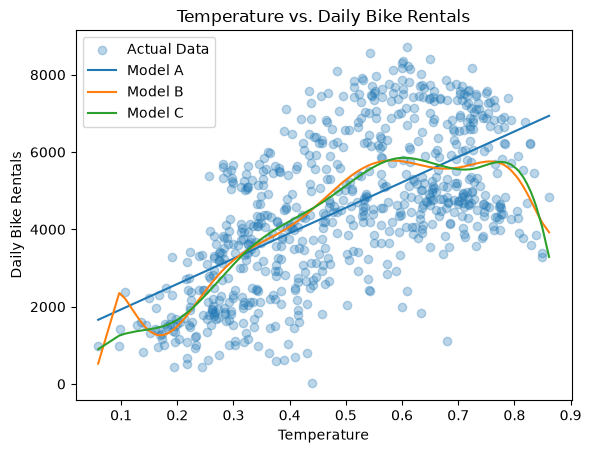

In [35]:
#sorting
X_sorted = X.sort_values("temp")

#bike rentals
plt.scatter(X["temp"], y, alpha=0.3, label="Actual Data")

#all models
plt.plot(X_sorted["temp"], model_A.predict(X_sorted), label="Model A")
plt.plot(X_sorted["temp"], model_B.predict(X_sorted), label="Model B")
plt.plot(X_sorted["temp"], model_C.predict(X_sorted), label="Model C")

plt.xlabel("Temperature")
plt.ylabel("Daily Bike Rentals")
plt.title("Temperature vs. Daily Bike Rentals")
plt.legend()
plt.show()


Question 2: Calculate the RMSE on in-sample (training) and out-of-sample (testing) data.

2a) Which model has the smallest training RMSE and which has the smallest test RMSE?

Model B has the smallest training and testing RMSE. 
- Model B Training RMSE: 1379.26
- Model B Testing RMSE: 1531.56

2b) Does decreasing the training error imply decreasing the test error? Use results from these models to support your answer.

No decreasing the training error does not imply decreasing the test error. 
Lower training error does not mean you will have a lower testing error, for example Model C has a higher testing RMSE than Model A. Also, Module C has a lower training RMSE than Model A. You would think that the testing and training RMSE would be lower for both for Model C, but it is not. 

2c) Is there any evidence of overfitting or underfitting in any of these models?

I would day that there is evidence for Model A to be underfitting because it is shown on the graph to be a linear increase, unlike Model B and C. 

Question 3: Rebuild Models A, B, and C, but this time use 5-fold cross-validation. Create a table 
comparing the following for each model: Training RMSE, Testing RMSE, k-fold RMSE. Does 
this give you more confidence in your answers around model complexity? Why or why not? 
ANSWER: 
This does give me more confidence in my answers around model complexity because it provides a deeper understanding in the results of over multiple splits. Model C presented the lowest 5 fold cross validationfor RMSE, while tested before for testing RMSE it shows Model B to be the lowest compared to the other two. This shows how the results are not reliable and should be cross validated. 

In [36]:
#Model A: 5-fold cross-validation
cv_A = cross_val_score(
    model_A, X, y,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

print("Model A 5-Fold CV RMSE:", -cv_A.mean())

Model A 5-Fold CV RMSE: 1834.696903394269


In [37]:
#Model C: 5-fold cross-validation
cv_C = cross_val_score(
    model_C, X, y,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

print("Model C 5-Fold CV RMSE:", -cv_C.mean())

Model C 5-Fold CV RMSE: 1775.4245864458892


In [38]:
#Model B: 5-fold cross-validation
cv_B = cross_val_score(
    model_B, X, y,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

print("Model B 5-Fold CV RMSE:", -cv_B.mean())

Model B 5-Fold CV RMSE: 1826.0982007554164


In [39]:
#comparing train,test, and 5 fold cross 
results = pd.DataFrame({
    "Model": ["A: Linear", "B: Polynomial", "C: Spline"],
    "Training RMSE": [train_rmse_A, train_rmse_B, train_rmse_C],
    "Testing RMSE": [test_rmse_A, test_rmse_B, test_rmse_C],
    "5-Fold CV RMSE": [-cv_A.mean(), -cv_B.mean(), -cv_C.mean()]
})

results.round(2)

,Model,Training RMSE,Testing RMSE,5-Fold CV RMSE
0,A: Linear,1497.67,1546.30,1834.70
1,B: Polynomial,1379.26,1531.56,1826.10
2,C: Spline,1382.83,1547.46,1775.42


AI USAGE:
Use of AI for question 1 and 2
I used GenAI to help explain concepts, such standard regression and cross validation, by suggesting a beginner friendly way to approach the problem. I did not rely on the generated answers without checking them with my class notebook examples and slides and I tested the code in Jupyter Notebook.

PART 4: The Bias-Variance Tradeoff (10 pts) 

Question 1: 6 pts] Let’s look at variance on the bike data for each of these models. Use the same train/test 
split you used in Part 3 to make the results directly comparable. For each of the three models in 
the previous question (Linear, Polynomial degree=9, and Cubic with 7 knots), do the bootstrap 
simulation described above. 

1a) Create a box plot of Predictions with each Model on the x-axis. Compare the distributions of predictions for each of the models. Which one is most stable? Which one appears most variable?
ANSWER: 
Model A has the smallest box and spread, while Model C appears to have the longest box and spread. It shows that Model A is the most stable and Model C appears the most variable. 

In [40]:
#bootstrapping
B = 500
rng = np.random.default_rng(42)

#predictions
pred_A = []
pred_B = []
pred_C = []

In [41]:
#temperature predictions
x0 = pd.DataFrame({"temp": [0.60]})

for i in range(B):
    #training 
    indices = rng.choice(len(X_train), size=len(X_train), replace=True)

    X_sample = X_train.iloc[indices]
    y_sample = y_train.iloc[indices]

    #refit
    for model, predictions in [
        (model_A, pred_A),
        (model_B, pred_B),
        (model_C, pred_C)
    ]:
        bootstrap_model = clone(model)
        bootstrap_model.fit(X_sample, y_sample)
        predictions.append(bootstrap_model.predict(x0)[0])

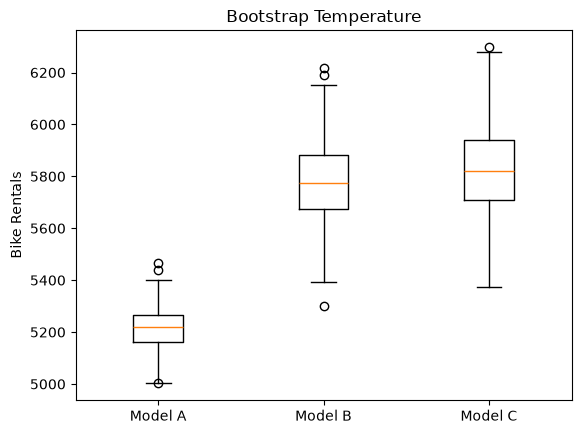

In [42]:
#boxplot
plt.boxplot(
    [pred_A, pred_B, pred_C],
    tick_labels=["Model A", "Model B", "Model C"]
)

plt.ylabel("Bike Rentals")
plt.title("Bootstrap Temperature")
plt.show()

1b) Compare prediction variability across the linear (A), polynomial (B), and spline (C) models. What does this tell you about the relationship between model flexibility and sensitivity to the training sample

ANSWER: Model C has the most sensitivity since its appears to have the largest spread compared to the other models. While Model A has the most flexibility since it appears to have the least variability and spread compared to the other models.

1c) More generally speaking, suppose a model fit the training observations very closely, but the predictions at temp=0.60 change substantially across bootstrap samples. What does this tell you about the model’s variance and its potential to generalize.

ANSWER: This means that the model's variance is high because the training observation has a wide variety. Also, the model's generalization is low because the training observation can be too big to generalize to all the data. 

Question 2: 

2a) Look at the bootstrap results, as well as the train/test RMSE and cv results, and the fitted 
curves, describe the bias variance tradeoff across the linear (A), polynomial (B), and 
spline (C) models. 

Model A has the highest Training, Testing, and 5 Fold RMSE showing that the is least flexiability and has the lowest variability compared to the other models. The graph shows a linear increase showing the least varibility/bias. 

Model B has the lowest Training and Testing RMSE showing that it is most flexiability compared to the other models.

Model C has the lowest 5 Fold RMSE 5 showing that it is most variability compared to the other models and means that is it most sensitive to other variables.

2b) A teammate says: “We should just choose the model with the smallest training RMSE.” 
Explain why this reasoning is incomplete. Use the ideas of bias, variance, overfitting, and 
generalization.

We cannot alome choose the model with the smallest training RMSE because it can be too generalized and overfitting for all the data. Ideally, we can test for variance and bias through cross validation. While when the variance can be high and bias can be low causing the predictions to depend on the sample. 

AI USAGE:
Use of AI for question 1 
I used GenAI to help explain concepts, such as bootstrapping, by suggesting a beginner friendly way to approach the problem. I did not rely on the generated answers without checking them with my class notebook examples and slides and I tested the code in Jupyter Notebook.